<h1>03. Data Checks and Graph Patterns</h1>

**What we do.** We run the project's formal data-quality checks (no self-loops, no duplicate edges, no missing labels, one connected component), then describe the basic shape of the network: label balance, degree distribution, edge-type composition, three centrality measures, and a first look at Louvain community sizes.

**What we get.** The data-quality table, basic network statistics, the label-distribution and degree-distribution figures, per-metric centrality leaderboards with their pairwise overlap, and a qualitative sample-network figure.

**Why this step matters.** Before running any classifier, it is worth knowing what kind of graph this actually is: how sparse it is, how imbalanced the two classes are, and whether a handful of hub nodes dominate the structure. These descriptive facts, especially the 84.5% same-field edge share, directly motivate RQ1 (can this structure be used for classification?) and set up the null-model comparison in RQ4 (is that 84.5% actually unusual?).

In [1]:
from pathlib import Path
import os
import sys
import warnings

def _find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root")

ROOT = _find_project_root(Path.cwd())
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
__name__ = "notebook_03"
print(f"Project root: {ROOT}")

Project root: C:\Users\Jimi\Desktop\github-social-network


<h2>Basic graph measures</h2>

Here we look at simple graph signals: how many neighbors nodes have, which nodes are central, how clustered the graph is, and how often links connect developers from the same field. These checks help us understand the graph before using it for prediction.

<h3>Source code: <code>src/graph_analysis.py</code></h3>

Computes descriptive network statistics: basic stats, label balance, edge-type counts, and homophily.

**`imports and constants`**

Imports the external libraries and project modules this file depends on, and defines the fixed constants (seeds, budgets, thresholds) shared by every function below.

In [ ]:
# -*- coding: utf-8 -*-
from typing import Any, Dict, Iterable

import networkx as nx
import pandas as pd

**`compute_basic_stats`**

Computes node/edge counts, density, mean degree, connected-component count, and label coverage directly from the graph and label table. These are the numbers reported at the top of notebook 03, and every later table is implicitly checked against them to confirm it still refers to the same 37,700-node, 289,003-edge graph.

In [ ]:
def compute_basic_stats(G: nx.Graph, labels_df: pd.DataFrame) -> Dict[str, Any]:
    """Compute core graph statistics for initial analysis."""
    num_nodes = G.number_of_nodes()
    num_edges = G.number_of_edges()
    density = nx.density(G) if num_nodes > 1 else 0.0
    average_degree = (2 * num_edges / num_nodes) if num_nodes > 0 else 0.0

    num_components = nx.number_connected_components(G) if num_nodes > 0 else 0
    largest_component_size = len(max(nx.connected_components(G), key=len)) if num_nodes > 0 else 0
    largest_component_ratio = (largest_component_size / num_nodes) if num_nodes > 0 else 0.0

    labeled_nodes_total = int(labels_df["id"].nunique())
    labeled_nodes_in_graph = int(labels_df["id"].isin(G.nodes()).sum())
    labeled_node_ratio = (labeled_nodes_in_graph / num_nodes) if num_nodes > 0 else 0.0

    return {
        "num_nodes": num_nodes,
        "num_edges": num_edges,
        "density": density,
        "average_degree": average_degree,
        "num_connected_components": num_components,
        "largest_component_size": largest_component_size,
        "largest_component_ratio": largest_component_ratio,
        "labeled_nodes_total": labeled_nodes_total,
        "labeled_nodes_in_graph": labeled_nodes_in_graph,
        "labeled_node_ratio": labeled_node_ratio,
    }

**`compute_label_distribution`**

Counts how many nodes fall into each class and returns both raw counts and percentages. The roughly 74% Web / 26% Machine Learning split this exposes is the reason every later model is scored with Balanced Accuracy, Macro F1, and ROC-AUC rather than plain Accuracy, which a majority-class model could inflate.

In [ ]:
def compute_label_distribution(labels_df: pd.DataFrame) -> pd.DataFrame:
    """Return label counts and ratios in a compact table."""
    counts = labels_df["label"].value_counts().sort_index()
    distribution_df = pd.DataFrame(
        {
            "label": counts.index.astype(int),
            "count": counts.values.astype(int),
        }
    )
    distribution_df["class_name"] = distribution_df["label"].map({0: "Web", 1: "Machine Learning"})
    distribution_df["ratio"] = distribution_df["count"] / distribution_df["count"].sum()

    return distribution_df

**`compute_edge_type_counts`**

Classifies every edge as Web-Web, ML-ML, or Web-ML by looking up both endpoint labels in one O(E) pass. The resulting counts are what later become the 84.5% same-field statistic that the RQ4 null models are built to test.

In [ ]:
def compute_edge_type_counts(G: nx.Graph, labels_dict: Dict[int, int]) -> Dict[str, int]:
    """
    Count edge types by endpoint labels:
    - web_web: both endpoints label 0
    - ml_ml: both endpoints label 1
    - web_ml: mixed labels
    - missing_label: at least one endpoint has no label
    """
    counts = {"web_web": 0, "ml_ml": 0, "web_ml": 0, "missing_label": 0}

    for u, v in G.edges():
        label_u = labels_dict.get(u)
        label_v = labels_dict.get(v)

        if label_u is None or label_v is None:
            counts["missing_label"] += 1
            continue

        if label_u == 0 and label_v == 0:
            counts["web_web"] += 1
        elif label_u == 1 and label_v == 1:
            counts["ml_ml"] += 1
        else:
            counts["web_ml"] += 1

    return counts

**`compute_homophily`**

Computes the same-label edge fraction and NetworkX's categorical assortativity coefficient side by side. The two agree in direction but are not identical: assortativity is normalized against what pure chance would produce given the class sizes, while the raw fraction is not, so reporting both avoids overselling either number on its own.

In [ ]:
def compute_homophily(G: nx.Graph, labels_dict: Dict[int, int]) -> Dict[str, float]:
    """Compute homophily based on the share of same-label edges among labeled edges."""
    edge_type_counts = compute_edge_type_counts(G, labels_dict)
    same_label_edges = edge_type_counts["web_web"] + edge_type_counts["ml_ml"]
    labeled_edges = same_label_edges + edge_type_counts["web_ml"]

    if labeled_edges == 0:
        homophily_rate = float("nan")
    else:
        homophily_rate = same_label_edges / labeled_edges

    return {
        "homophily_rate": homophily_rate,
        "same_label_edges": same_label_edges,
        "different_label_edges": edge_type_counts["web_ml"],
        "labeled_edges": labeled_edges,
    }

**`compute_label_assortativity`**

Wraps NetworkX's assortativity computation on a labeled subgraph, with an optional node subset. Restricting that subset to training nodes is what lets a later notebook compute a train-only version of this statistic without leaking test labels into a diagnostic number.

In [ ]:
def compute_label_assortativity(
    G: nx.Graph,
    labels_dict: Dict[int, int],
    nodes: Iterable[int] | None = None,
) -> float:

    if nodes is None:
        candidate_nodes = [int(node) for node in G.nodes() if int(node) in labels_dict]
    else:
        candidate_nodes = [int(node) for node in nodes if int(node) in G and int(node) in labels_dict]

    if len(candidate_nodes) < 2:
        return float("nan")

    subgraph = G.subgraph(candidate_nodes).copy()
    if subgraph.number_of_edges() == 0:
        return float("nan")

    nx.set_node_attributes(subgraph, {node: int(labels_dict[node]) for node in candidate_nodes}, "label")
    return float(nx.attribute_assortativity_coefficient(subgraph, "label"))

<h3>Source code: <code>src/visualization.py</code></h3>

Creates the saved figures used throughout the notebooks, each with explicit titles, axes, and legends.

**`imports and constants`**

Imports the external libraries and project modules this file depends on, and defines the fixed constants (seeds, budgets, thresholds) shared by every function below.

In [ ]:
# -*- coding: utf-8 -*-
from pathlib import Path
from typing import Dict

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns


sns.set_theme(style="whitegrid")

**`plot_label_distribution`**

Saves the Web vs. Machine Learning bar chart shown early in notebook 03, with an explicit title and axis labels rather than matplotlib's bare defaults.

In [ ]:
def _prepare_output_dir(output_dir: str | Path) -> Path:
    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)
    return output_path


def plot_label_distribution(label_distribution_df: pd.DataFrame, output_dir: str | Path) -> Path:
    """Plot and save label distribution (Web vs ML)."""
    output_path = _prepare_output_dir(output_dir) / "label_distribution.png"

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.barplot(data=label_distribution_df, x="class_name", y="count", hue="class_name", legend=False, palette="Set2", ax=ax)
    ax.set_title("GitHub Developers by Label", fontsize=13, weight="bold")
    ax.set_xlabel("Label")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=10)

    for idx, row in label_distribution_df.reset_index(drop=True).iterrows():
        ax.text(idx, row["count"], f"{row['count']:,}", ha="center", va="bottom", fontsize=10)

    fig.tight_layout()
    fig.savefig(output_path, dpi=300)
    plt.close(fig)

    return output_path

**`plot_degree_distribution`**

Saves a log-log degree histogram, used to visually motivate the power-law tail check performed later in the null-model notebook.

In [ ]:
def plot_degree_distribution(G: nx.Graph, output_dir: str | Path) -> Path:
    """Plot and save degree distribution histogram."""
    output_path = _prepare_output_dir(output_dir) / "degree_distribution.png"
    degrees = [degree for _, degree in G.degree()]

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.histplot(degrees, bins=60, color="#2ca02c", ax=ax)
    ax.set_title("Degree Distribution", fontsize=13, weight="bold")
    ax.set_xlabel("Degree")
    ax.set_ylabel("Number of Nodes")

    fig.tight_layout()
    fig.savefig(output_path, dpi=300)
    plt.close(fig)

    return output_path

**`plot_edge_type_distribution`**

Saves the Web-Web / ML-ML / Web-ML edge-count bar chart that visually backs the homophily statistic computed above.

In [ ]:
def plot_edge_type_distribution(edge_type_counts: Dict[str, int], output_dir: str | Path) -> Path:
    """Plot and save distribution of edge types by node labels."""
    output_path = _prepare_output_dir(output_dir) / "edge_type_distribution.png"

    label_map = {
        "web_web": "Web-Web",
        "ml_ml": "ML-ML",
        "web_ml": "Web-ML",
        "missing_label": "Missing Label",
    }

    plot_df = pd.DataFrame(
        {
            "edge_type": [label_map[key] for key in label_map],
            "count": [edge_type_counts.get(key, 0) for key in label_map],
        }
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=plot_df, x="edge_type", y="count", hue="edge_type", legend=False, palette="Blues", ax=ax)
    ax.set_title("Edge Type Distribution", fontsize=13, weight="bold")
    ax.set_xlabel("Edge Type")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=10)

    for idx, row in plot_df.reset_index(drop=True).iterrows():
        ax.text(idx, row["count"], f"{int(row['count']):,}", ha="center", va="bottom", fontsize=10)

    fig.tight_layout()
    fig.savefig(output_path, dpi=300)
    plt.close(fig)

    return output_path

**`plot_sampled_network`**

Draws a random sample of nodes, not the full 37,700-node graph which would be unreadable and slow to lay out, colored by label as a qualitative illustration only; the caption in the notebook explicitly warns this plot is not a basis for quantitative claims.

In [ ]:
def plot_sampled_network(
    G: nx.Graph,
    labels_dict: Dict[int, int],
    partition: Dict[int, int],
    community_summary_df: pd.DataFrame,
    output_dir: str | Path,
    sample_size: int = 350,
    random_state: int = 42,
) -> Path:
    """Plot a readable sampled developer network colored by label."""
    output_path = _prepare_output_dir(output_dir) / "sampled_network_by_label.png"
    rng = np.random.default_rng(random_state)

    top_communities = (
        community_summary_df.sort_values("size", ascending=False)["community_id"]
        .astype(int)
        .head(4)
        .tolist()
    )
    nodes_by_community: Dict[int, list[int]] = {community_id: [] for community_id in top_communities}
    for node, community_id in partition.items():
        community_id_int = int(community_id)
        if community_id_int in nodes_by_community and int(node) in labels_dict:
            nodes_by_community[community_id_int].append(int(node))

    sampled_nodes: list[int] = []
    per_community = max(1, sample_size // max(1, len(top_communities)))
    for community_id, nodes in nodes_by_community.items():
        ranked_nodes = sorted(nodes, key=lambda node: G.degree(node), reverse=True)
        head = ranked_nodes[: min(len(ranked_nodes), per_community * 2)]
        if len(head) > per_community:
            selected = rng.choice(head, size=per_community, replace=False).tolist()
        else:
            selected = head
        sampled_nodes.extend(int(node) for node in selected)

    sampled_nodes = list(dict.fromkeys(sampled_nodes))[:sample_size]
    subgraph = G.subgraph(sampled_nodes).copy()

    label_colors = {0: "#4C78A8", 1: "#F58518"}
    node_colors = [label_colors.get(int(labels_dict.get(node, 0)), "#999999") for node in subgraph.nodes()]
    node_sizes = [35 + min(120, G.degree(node) * 2) for node in subgraph.nodes()]

    fig, ax = plt.subplots(figsize=(10, 8))
    pos = nx.spring_layout(subgraph, seed=random_state, k=0.22, iterations=80)
    nx.draw_networkx_edges(subgraph, pos, ax=ax, alpha=0.12, width=0.5, edge_color="#555555")
    nx.draw_networkx_nodes(
        subgraph,
        pos,
        ax=ax,
        node_color=node_colors,
        node_size=node_sizes,
        linewidths=0.2,
        edgecolors="#222222",
        alpha=0.9,
    )

    ax.set_title("Sampled GitHub Developer Network Colored by Label", fontsize=13, weight="bold")
    ax.set_axis_off()
    handles = [
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=label_colors[0], label="Web", markersize=8),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor=label_colors[1],
            label="Machine Learning",
            markersize=8,
        ),
    ]
    ax.legend(handles=handles, loc="lower left", frameon=True)

    fig.tight_layout()
    fig.savefig(output_path, dpi=300)
    plt.close(fig)

    return output_path

**`plot_community_purity_error_rates`**

Saves the bar chart of classification error rate against community-purity bucket, the figure that visually backs the community-purity error-analysis table added to notebook 05.

In [ ]:
def plot_community_purity_error_rates(error_by_purity_df: pd.DataFrame, output_dir: str | Path) -> Path:
    output_path = _prepare_output_dir(output_dir) / "community_purity_error_analysis.png"

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=error_by_purity_df, x="purity_group", y="error_rate", color="#D55E00", ax=ax)
    ax.set_title("Error Rate by Community Purity", fontsize=13, weight="bold")
    ax.set_xlabel("Community Purity Group")
    ax.set_ylabel("Error Rate")
    ax.tick_params(axis="x", rotation=12)

    for idx, row in error_by_purity_df.reset_index(drop=True).iterrows():
        if pd.isna(row["error_rate"]):
            continue
        ax.text(idx, row["error_rate"], f"{row['error_rate']:.3f}", ha="center", va="bottom", fontsize=10)

    fig.tight_layout()
    fig.savefig(output_path, dpi=300)
    plt.close(fig)

    return output_path

**`plot_error_type_counts`**

Saves a breakdown of correct vs. incorrect predictions by class-transition type (Web kept Web, Web mispredicted as ML, and so on), giving a more granular view of failure modes than a single accuracy number.

In [ ]:
def plot_error_type_counts(error_types_df: pd.DataFrame, output_dir: str | Path) -> Path:
    output_path = _prepare_output_dir(output_dir) / "prediction_error_types.png"

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=error_types_df, x="error_type", y="count", hue="error_type", legend=False, palette="Set2", ax=ax)
    ax.set_title("Prediction Outcomes by Type", fontsize=13, weight="bold")
    ax.set_xlabel("Prediction Type")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=12)

    for idx, row in error_types_df.reset_index(drop=True).iterrows():
        ax.text(idx, row["count"], f"{int(row['count']):,}", ha="center", va="bottom", fontsize=10)

    fig.tight_layout()
    fig.savefig(output_path, dpi=300)
    plt.close(fig)

    return output_path

<h3>Source code: <code>src/run_core_analysis.py</code></h3>

Orchestrates data-quality checks, descriptive statistics, centrality, and Louvain into the notebook 03 tables and figures.

**`imports and constants`**

Imports the external libraries and project modules this file depends on, and defines the fixed constants (seeds, budgets, thresholds) shared by every function below.

In [ ]:
from itertools import combinations
from pathlib import Path
import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

SRC_DIR = Path(__file__).resolve().parent
PROJECT_DIR = SRC_DIR.parent
sys.path.insert(0, str(SRC_DIR))

from community_analysis import (
    detect_louvain_communities,
    summarize_communities,
)
from data_loader import load_dataset
from graph_analysis import (
    compute_basic_stats,
    compute_edge_type_counts,
    compute_homophily,
    compute_label_distribution,
)
from visualization import (
    plot_degree_distribution,
    plot_edge_type_distribution,
    plot_label_distribution,
    plot_sampled_network,
)


SEED = 42
TOP_K = 10
OVERLAP_K = 20
BETWEENNESS_SAMPLES = 100

**`main`**

Runs data-quality checks, basic network statistics, centrality tables, and Louvain, and saves every table and figure used earlier in this notebook.

In [ ]:
def _data_quality_table(
    G: nx.Graph, edges_df: pd.DataFrame, labels_df: pd.DataFrame
) -> pd.DataFrame:
    canonical = pd.DataFrame(
        {
            "u": edges_df[["id_1", "id_2"]].min(axis=1),
            "v": edges_df[["id_1", "id_2"]].max(axis=1),
        }
    )
    checks = [
        ("raw_edge_rows", int(len(edges_df)), True),
        ("graph_nodes", int(G.number_of_nodes()), True),
        ("graph_edges", int(G.number_of_edges()), True),
        ("self_loops", int(nx.number_of_selfloops(G)), nx.number_of_selfloops(G) == 0),
        (
            "duplicate_undirected_edges",
            int(canonical.duplicated().sum()),
            not canonical.duplicated().any(),
        ),
        (
            "duplicate_label_ids",
            int(labels_df["id"].duplicated().sum()),
            not labels_df["id"].duplicated().any(),
        ),
        (
            "missing_labels",
            int(labels_df["label"].isna().sum()),
            not labels_df["label"].isna().any(),
        ),
        (
            "all_graph_nodes_labeled",
            int(set(G.nodes()) <= set(labels_df["id"])),
            set(G.nodes()) <= set(labels_df["id"]),
        ),
        (
            "connected_components",
            int(nx.number_connected_components(G)),
            nx.is_connected(G),
        ),
    ]
    return pd.DataFrame(checks, columns=["check", "value", "passed"])


def _centrality_tables(
    G: nx.Graph, labels_df: pd.DataFrame
) -> tuple[pd.DataFrame, pd.DataFrame]:
    print("Computing centralities ...")
    degree = nx.degree_centrality(G)
    pagerank = nx.pagerank(G)
    betweenness = nx.betweenness_centrality(
        G, k=BETWEENNESS_SAMPLES, seed=SEED, normalized=True
    )
    clustering = nx.clustering(G)
    try:
        hits_hub, _ = nx.hits(G, max_iter=800)
    except nx.PowerIterationFailedConvergence:
        hits_hub = {int(node): float("nan") for node in G}

    metrics = {
        "Degree Centrality": degree,
        "PageRank": pagerank,
        f"Betweenness Centrality (approx., k={BETWEENNESS_SAMPLES})": betweenness,
        "Clustering Coefficient": clustering,
        "HITS Hub": hits_hub,
    }
    metadata = labels_df.set_index("id")
    top_rows: list[dict] = []
    top_sets: dict[str, set[int]] = {}
    for metric_name, scores in metrics.items():
        ranked = sorted(
            ((int(node), float(score)) for node, score in scores.items()),
            key=lambda item: item[1],
            reverse=True,
        )
        top_sets[metric_name] = {node for node, _ in ranked[:OVERLAP_K]}
        for rank, (node, score) in enumerate(ranked[:TOP_K], start=1):
            label = int(metadata.at[node, "label"])
            top_rows.append(
                {
                    "metric": metric_name,
                    "rank": rank,
                    "node_id": node,
                    "developer_name": str(metadata.at[node, "name"])
                    if "name" in metadata.columns
                    else str(node),
                    "field": "Machine Learning" if label == 1 else "Web",
                    "score": score,
                    "degree": int(G.degree(node)),
                    "pagerank": float(pagerank[node]),
                    "betweenness_approx": float(betweenness[node]),
                    "clustering_coefficient": float(clustering[node]),
                }
            )

    overlap_rows = []
    for metric_a, metric_b in combinations(top_sets, 2):
        set_a, set_b = top_sets[metric_a], top_sets[metric_b]
        intersection = len(set_a & set_b)
        union = len(set_a | set_b)
        overlap_rows.append(
            {
                "metric_a": metric_a,
                "metric_b": metric_b,
                "top_k": OVERLAP_K,
                "intersection_count": intersection,
                "jaccard_overlap": intersection / union if union else 0.0,
            }
        )
    return pd.DataFrame(top_rows), pd.DataFrame(overlap_rows)


def _plot_communities(
    community_df: pd.DataFrame, figures_dir: Path
) -> None:
    top = community_df.head(12).sort_values("size")
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(
        top["community_id"].astype(str),
        top["web_count"],
        label="Web",
        color="#315C8D",
    )
    ax.barh(
        top["community_id"].astype(str),
        top["ml_count"],
        left=top["web_count"],
        label="Machine Learning",
        color="#D57837",
    )
    ax.set_xlabel("Developers")
    ax.set_ylabel("Louvain community ID")
    ax.set_title("Twelve largest Louvain communities: size and field composition")
    ax.legend(loc="lower right")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(
        figures_dir / "community_size_and_composition.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 5.5))
    sizes = community_df["size"].sort_values(ascending=False).to_numpy()
    ax.plot(np.arange(1, len(sizes) + 1), sizes, marker="o", color="#315C8D")
    ax.set_yscale("log")
    ax.set_xlabel("Community rank by size")
    ax.set_ylabel("Number of developers (log scale)")
    ax.set_title("Louvain community-size distribution")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(
        figures_dir / "community_size_distribution.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)


def main() -> None:
    data_dir = PROJECT_DIR / "data"
    tables_dir = PROJECT_DIR / "outputs" / "tables"
    figures_dir = PROJECT_DIR / "outputs" / "figures"
    tables_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    G, edges_df, labels_df, labels_dict = load_dataset(data_dir)
    quality_df = _data_quality_table(G, edges_df, labels_df)
    if not quality_df["passed"].all():
        raise AssertionError(
            quality_df.loc[~quality_df["passed"]].to_string(index=False)
        )

    basic_stats = compute_basic_stats(G, labels_df)
    homophily = compute_homophily(G, labels_dict)
    basic_df = pd.DataFrame([{**basic_stats, **homophily}])
    label_df = compute_label_distribution(labels_df)
    edge_counts = compute_edge_type_counts(G, labels_dict)
    edge_df = pd.DataFrame(
        [
            {"edge_type": key, "count": int(value)}
            for key, value in edge_counts.items()
        ]
    )

    partition, modularity = detect_louvain_communities(
        G, random_state=SEED
    )
    community_df = summarize_communities(G, labels_dict, partition)
    community_metrics_df = pd.DataFrame(
        [
            {
                "number_of_communities": int(community_df.shape[0]),
                "modularity": float(modularity),
                "largest_community_size": int(community_df["size"].max()),
                "median_community_size": float(community_df["size"].median()),
                "size_weighted_mean_purity": float(
                    np.average(community_df["purity"], weights=community_df["size"])
                ),
            }
        ]
    )

    centrality_df, overlap_df = _centrality_tables(G, labels_df)

    tables = {
        "data_quality_checks.csv": quality_df,
        "network_basic_stats.csv": basic_df,
        "label_distribution.csv": label_df,
        "edge_type_counts.csv": edge_df,
        "community_summary.csv": community_df,
        "community_metrics.csv": community_metrics_df,
        "centrality_top_developers.csv": centrality_df,
        "centrality_top_overlap.csv": overlap_df,
    }
    for filename, frame in tables.items():
        frame.to_csv(tables_dir / filename, index=False)

    plot_label_distribution(label_df, figures_dir)
    plot_degree_distribution(G, figures_dir)
    plot_edge_type_distribution(edge_counts, figures_dir)
    plot_sampled_network(
        G,
        labels_dict,
        partition,
        community_df,
        figures_dir,
        sample_size=350,
        random_state=SEED,
    )
    _plot_communities(community_df, figures_dir)

    print("Core analysis completed.")
    print(basic_df.to_string(index=False))
    print(community_metrics_df.to_string(index=False))

**`__main__ guard`**

Keeps the original command-line entry guard from the source file; it stays inactive here because the run cell below calls the pipeline directly.

In [ ]:
if __name__ == "__main__":
    main()

<h2>Run this step</h2>

Run the data checks, graph summaries, centrality tables, community tables, and saved figures.

In [11]:
from run_core_analysis import main as run_core_analysis

run_core_analysis()

Computing centralities ...


Core analysis completed.
 num_nodes  num_edges  density  average_degree  num_connected_components  largest_component_size  largest_component_ratio  labeled_nodes_total  labeled_nodes_in_graph  labeled_node_ratio  homophily_rate  same_label_edges  different_label_edges  labeled_edges
     37700     289003 0.000407       15.331724                         1                   37700                      1.0                37700                   37700                 1.0        0.845344            244307                  44696         289003
 number_of_communities  modularity  largest_community_size  median_community_size  size_weighted_mean_purity
                    31    0.453448                    8732                    9.0                   0.829788


Then we read the saved tables and figures.

<h3>Table: <code>outputs/tables/data_quality_checks.csv</code></h3>

Physical and logical checks on the raw graph inputs.

In [12]:
quality = pd.read_csv(ROOT / 'outputs/tables/data_quality_checks.csv')
display(quality)

,check,value,passed
0,raw_edge_rows,289003,True
1,graph_nodes,37700,True
2,graph_edges,289003,True
3,self_loops,0,True
4,duplicate_undirected_edges,0,True
5,duplicate_label_ids,0,True
6,missing_labels,0,True
7,all_graph_nodes_labeled,1,True
8,connected_components,1,True


**Conclusion.** All checks must pass; failures would invalidate every downstream result.

<h3>Table: <code>outputs/tables/label_distribution.csv</code></h3>

Counts and shares for Web and Machine Learning developers.

In [13]:
labels = pd.read_csv(ROOT / 'outputs/tables/label_distribution.csv')
display(labels)

,label,count,class_name,ratio
0,0,27961,Web,0.741671
1,1,9739,Machine Learning,0.258329


**Conclusion.** About three quarters of nodes are Web, so Balanced Accuracy, F1, and ROC-AUC are needed alongside Accuracy.

<h3>Figure: <code>label_distribution.png</code></h3>

This bar chart visualizes the class counts in the preceding table.

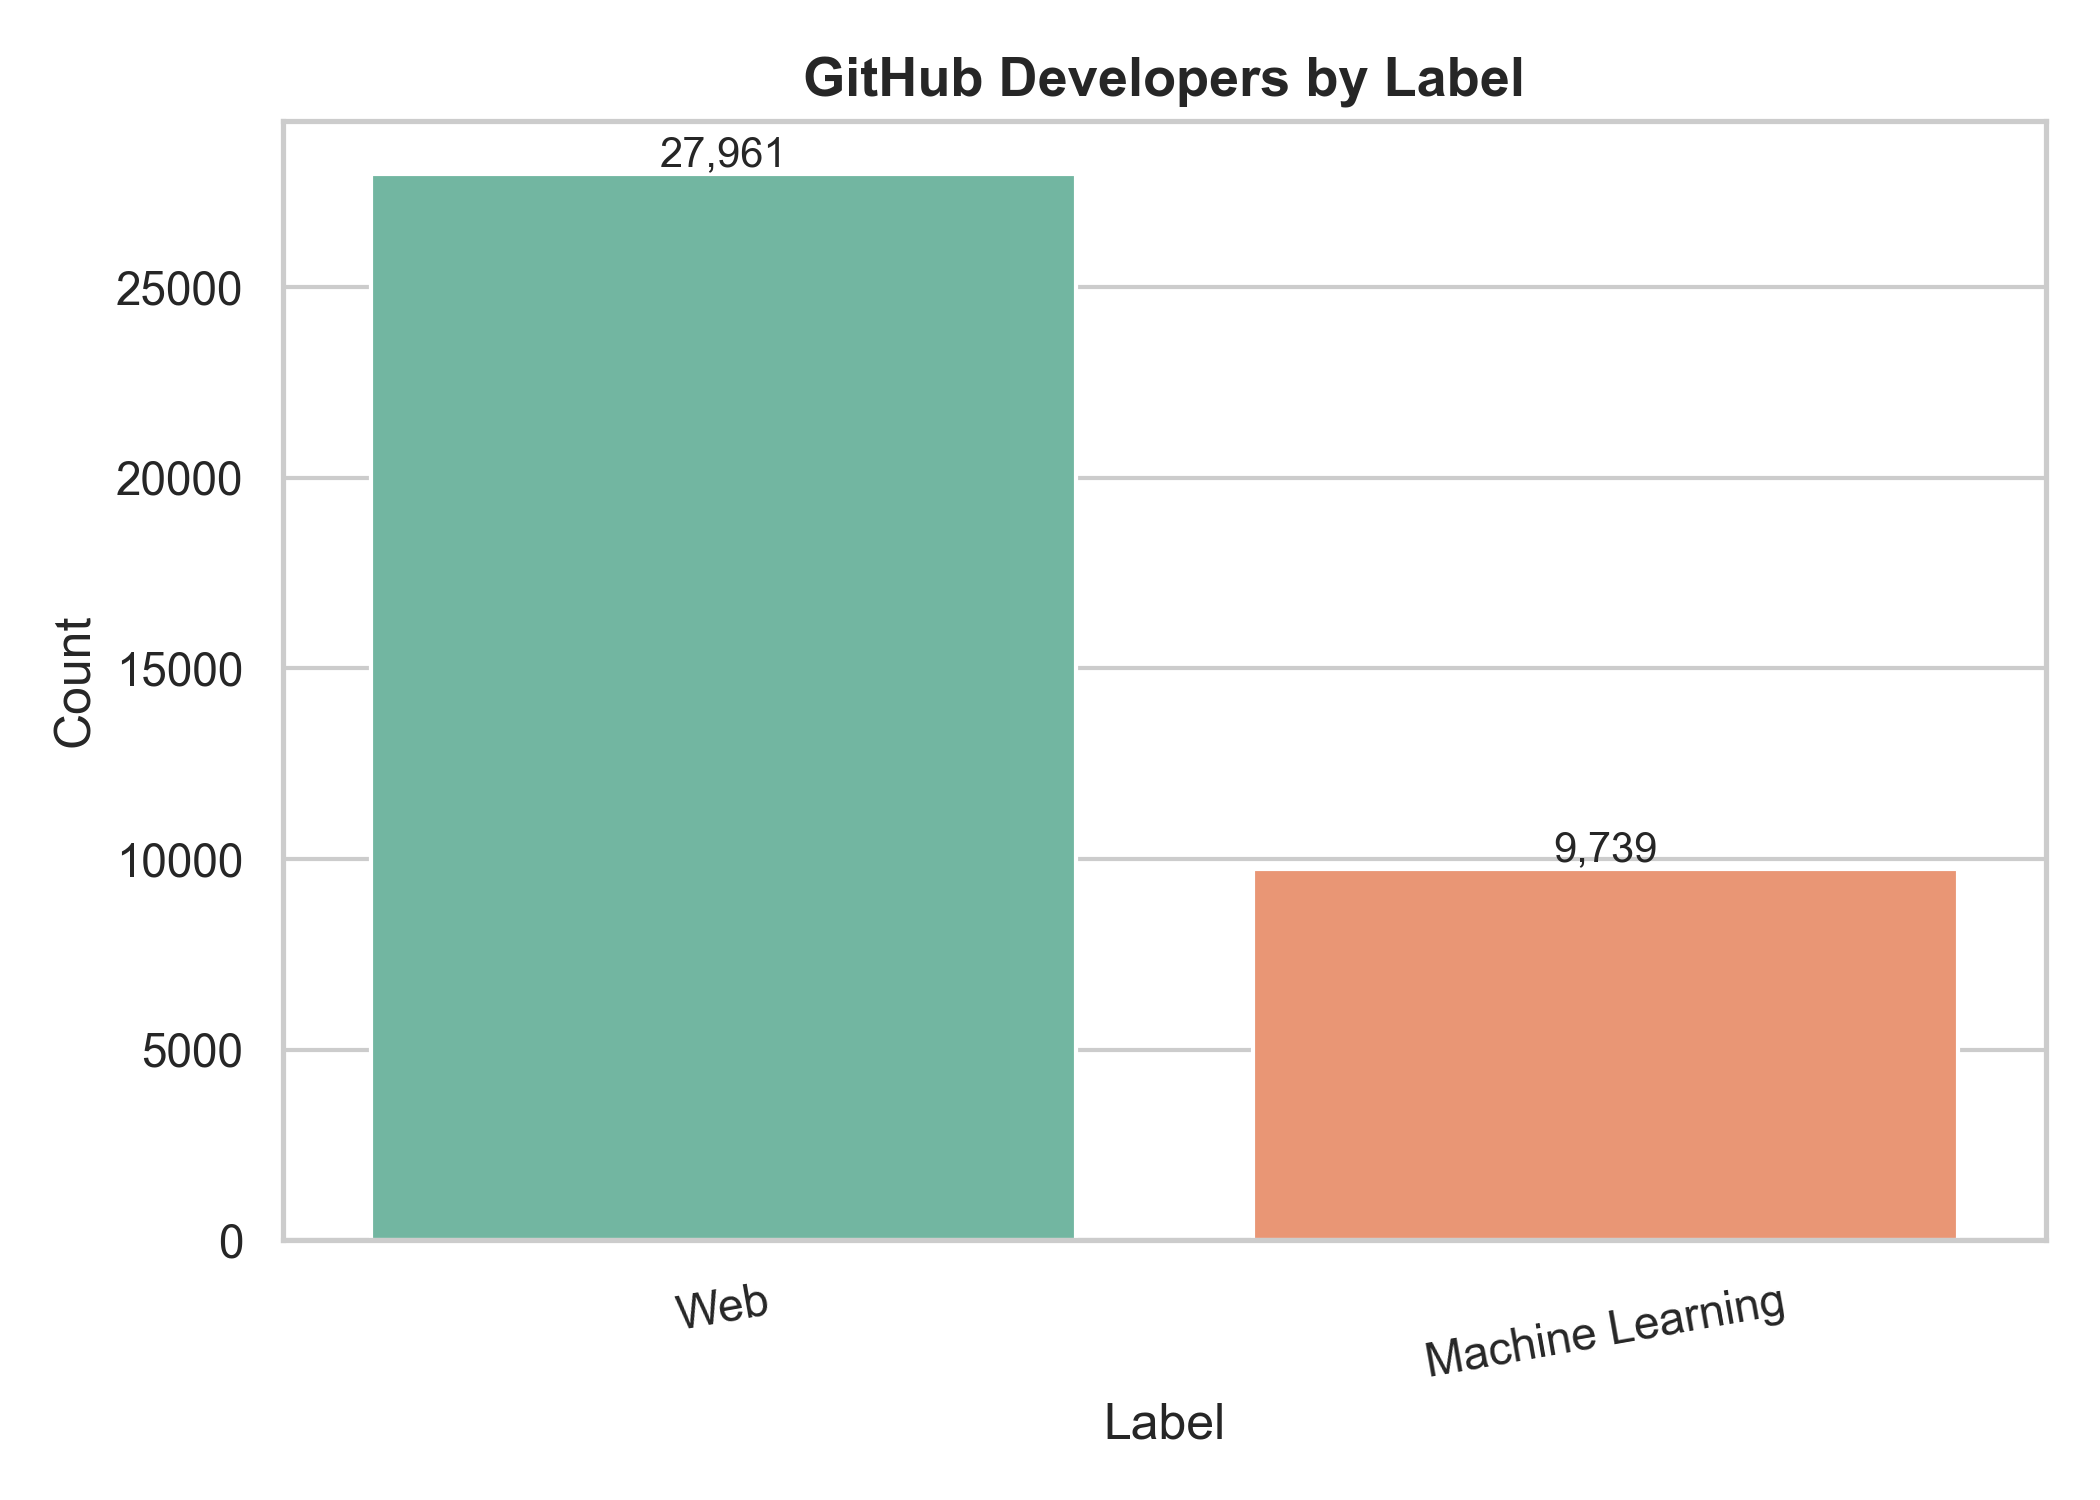

In [14]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/figures/label_distribution.png')))

**Figure note.** The visible imbalance explains why a majority classifier can have acceptable Accuracy while failing completely on the ML class.

<h3>Table: <code>outputs/tables/network_basic_stats.csv</code></h3>

Core network size, density, connectivity, and mixing statistics.

In [15]:
network_stats = pd.read_csv(ROOT / 'outputs/tables/network_basic_stats.csv')
display(network_stats)

,num_nodes,num_edges,density,average_degree,num_connected_components,largest_component_size,largest_component_ratio,labeled_nodes_total,labeled_nodes_in_graph,labeled_node_ratio,homophily_rate,same_label_edges,different_label_edges,labeled_edges
0,37700,289003,0.000407,15.331724,1,37700,1.0,37700,37700,1.0,0.845344,244307,44696,289003


**Conclusion.** The network is sparse but strongly homophilous, motivating both predictive evaluation and null-model controls.

<h3>Figure: <code>degree_distribution.png</code></h3>

This figure expands the mean-degree summary into the complete measured degree distribution.

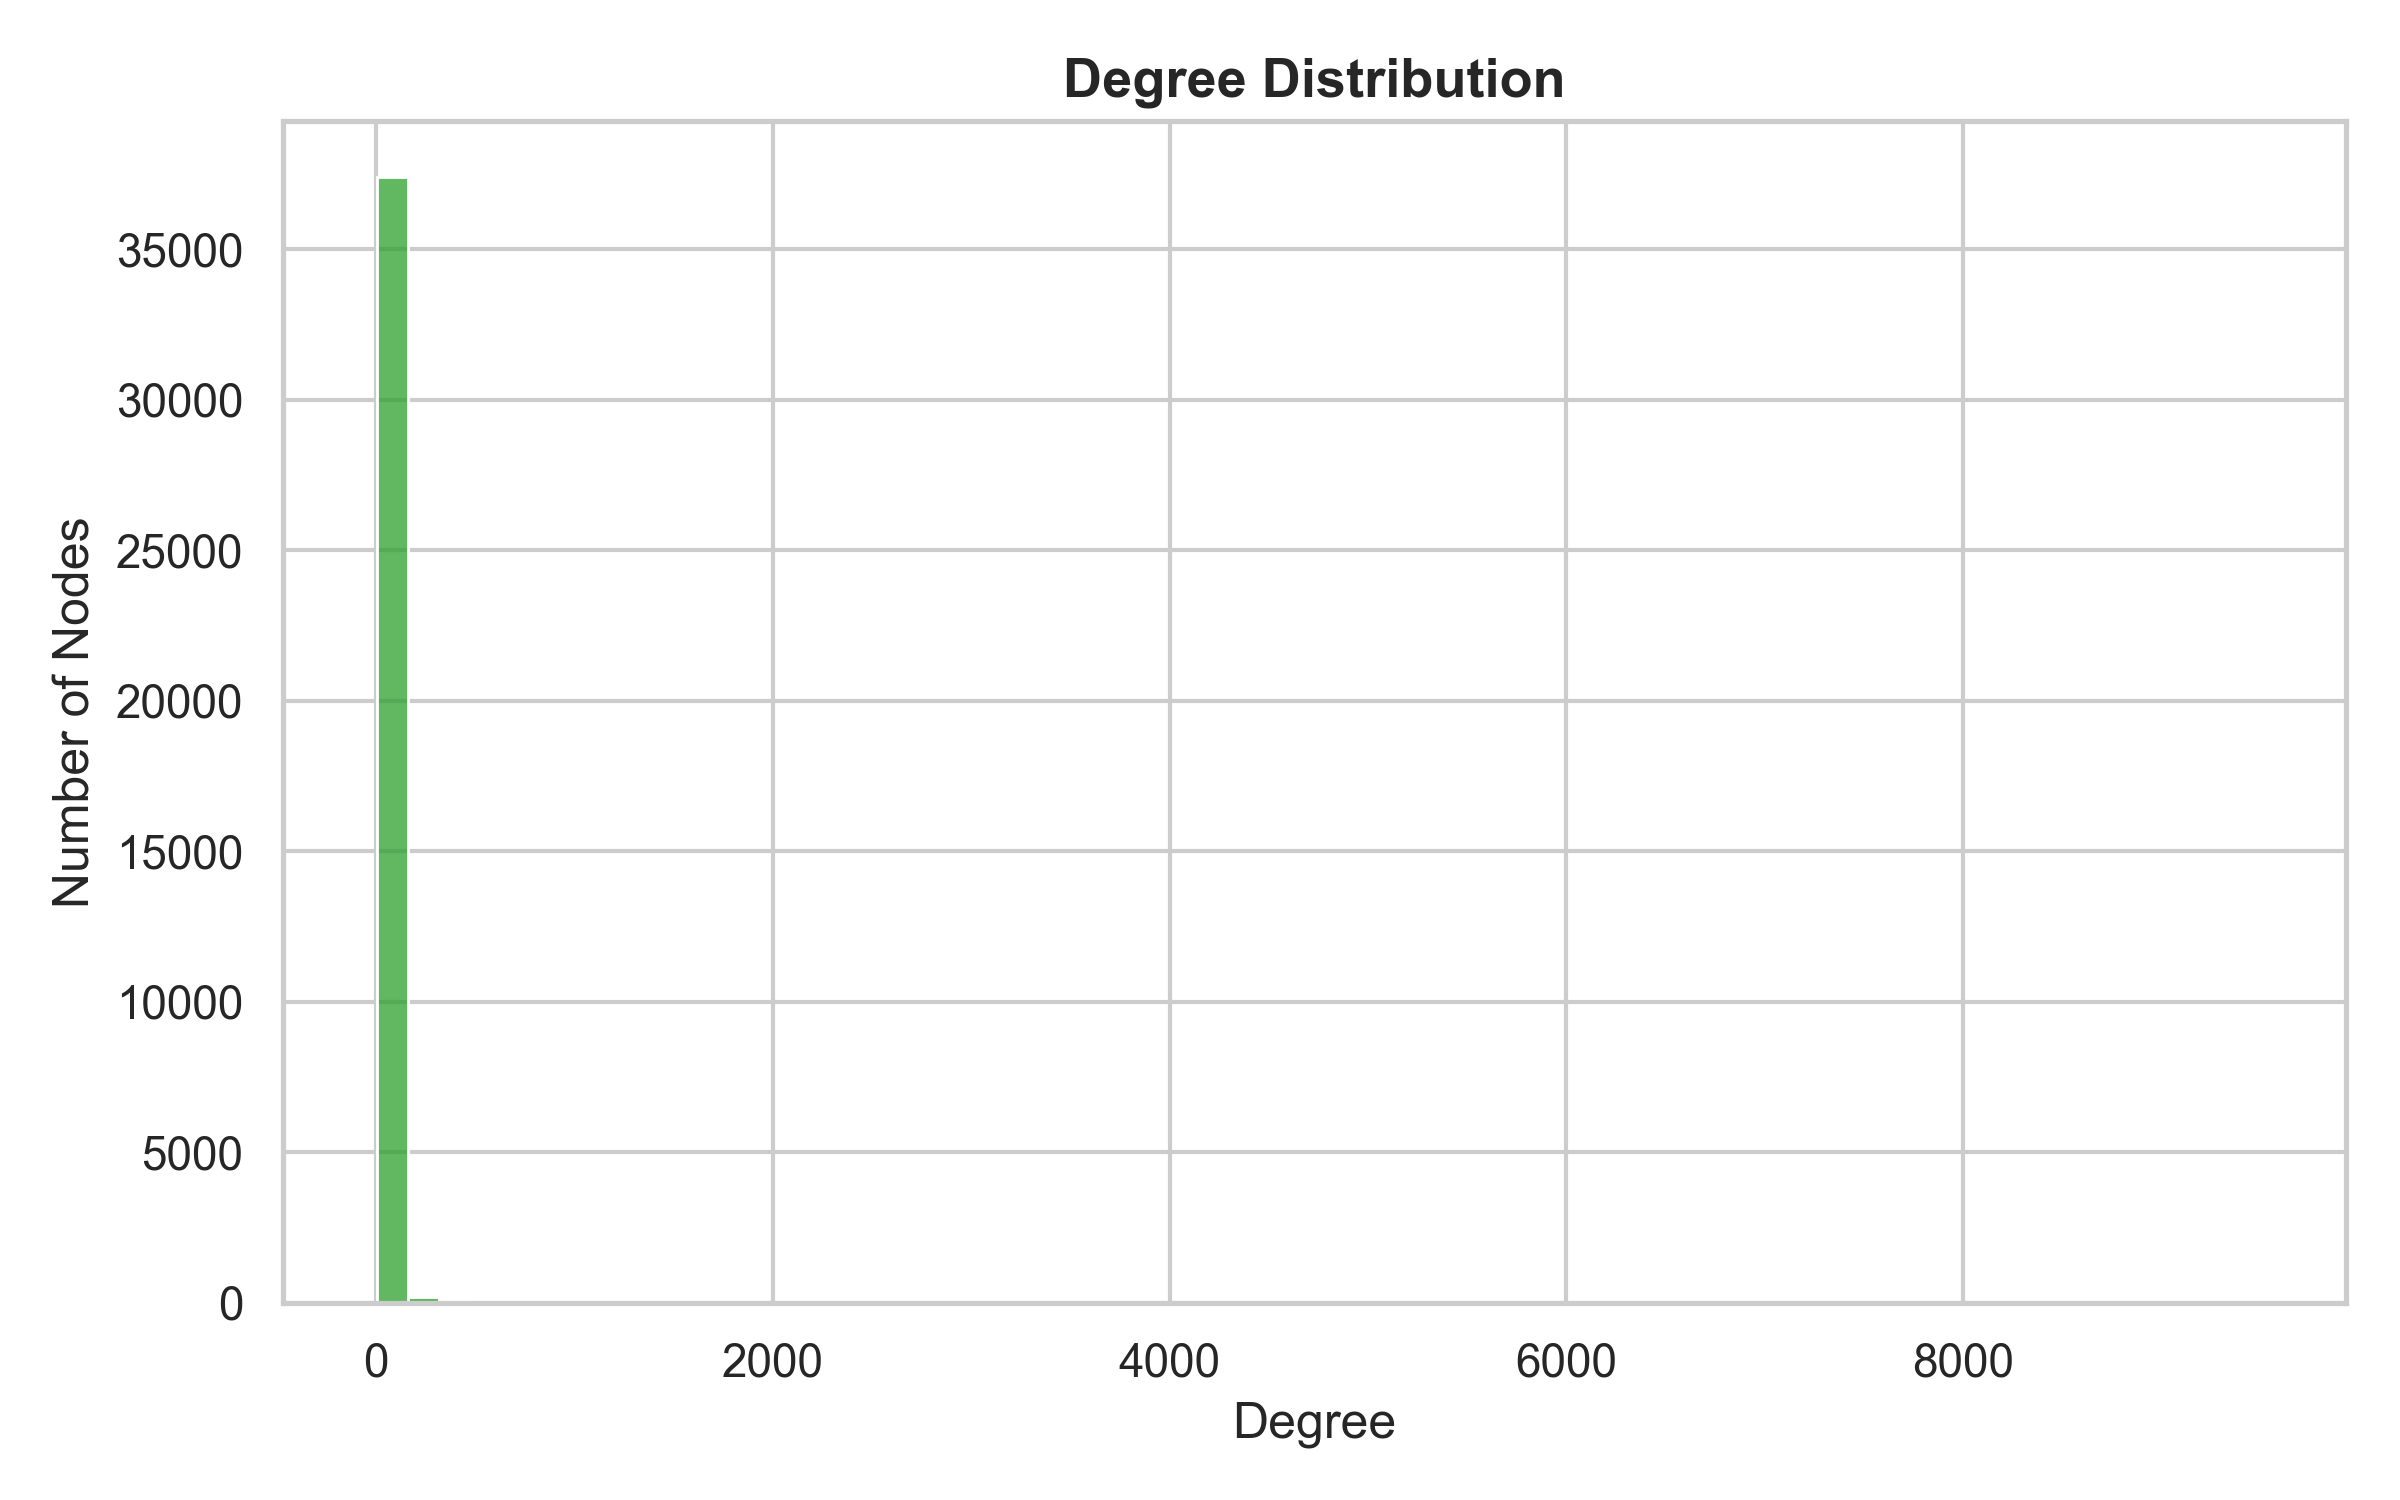

In [16]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/figures/degree_distribution.png')))

**Figure note.** Most developers have modest degree while a small number are very large hubs, so average degree alone hides substantial heterogeneity.

<h3>Table: <code>outputs/tables/edge_type_counts.csv</code></h3>

Counts of Web-Web, ML-ML, and cross-field mutual-follow edges.

In [17]:
edge_types = pd.read_csv(ROOT / 'outputs/tables/edge_type_counts.csv')
display(edge_types)

,edge_type,count
0,web_web,224623
1,ml_ml,19684
2,web_ml,44696
3,missing_label,0


**Conclusion.** Within-field edges dominate, but the class imbalance means this based on this dataset pattern still requires random comparisons.

<h3>Figure: <code>edge_type_distribution.png</code></h3>

This figure translates the edge-type counts into a direct composition comparison.

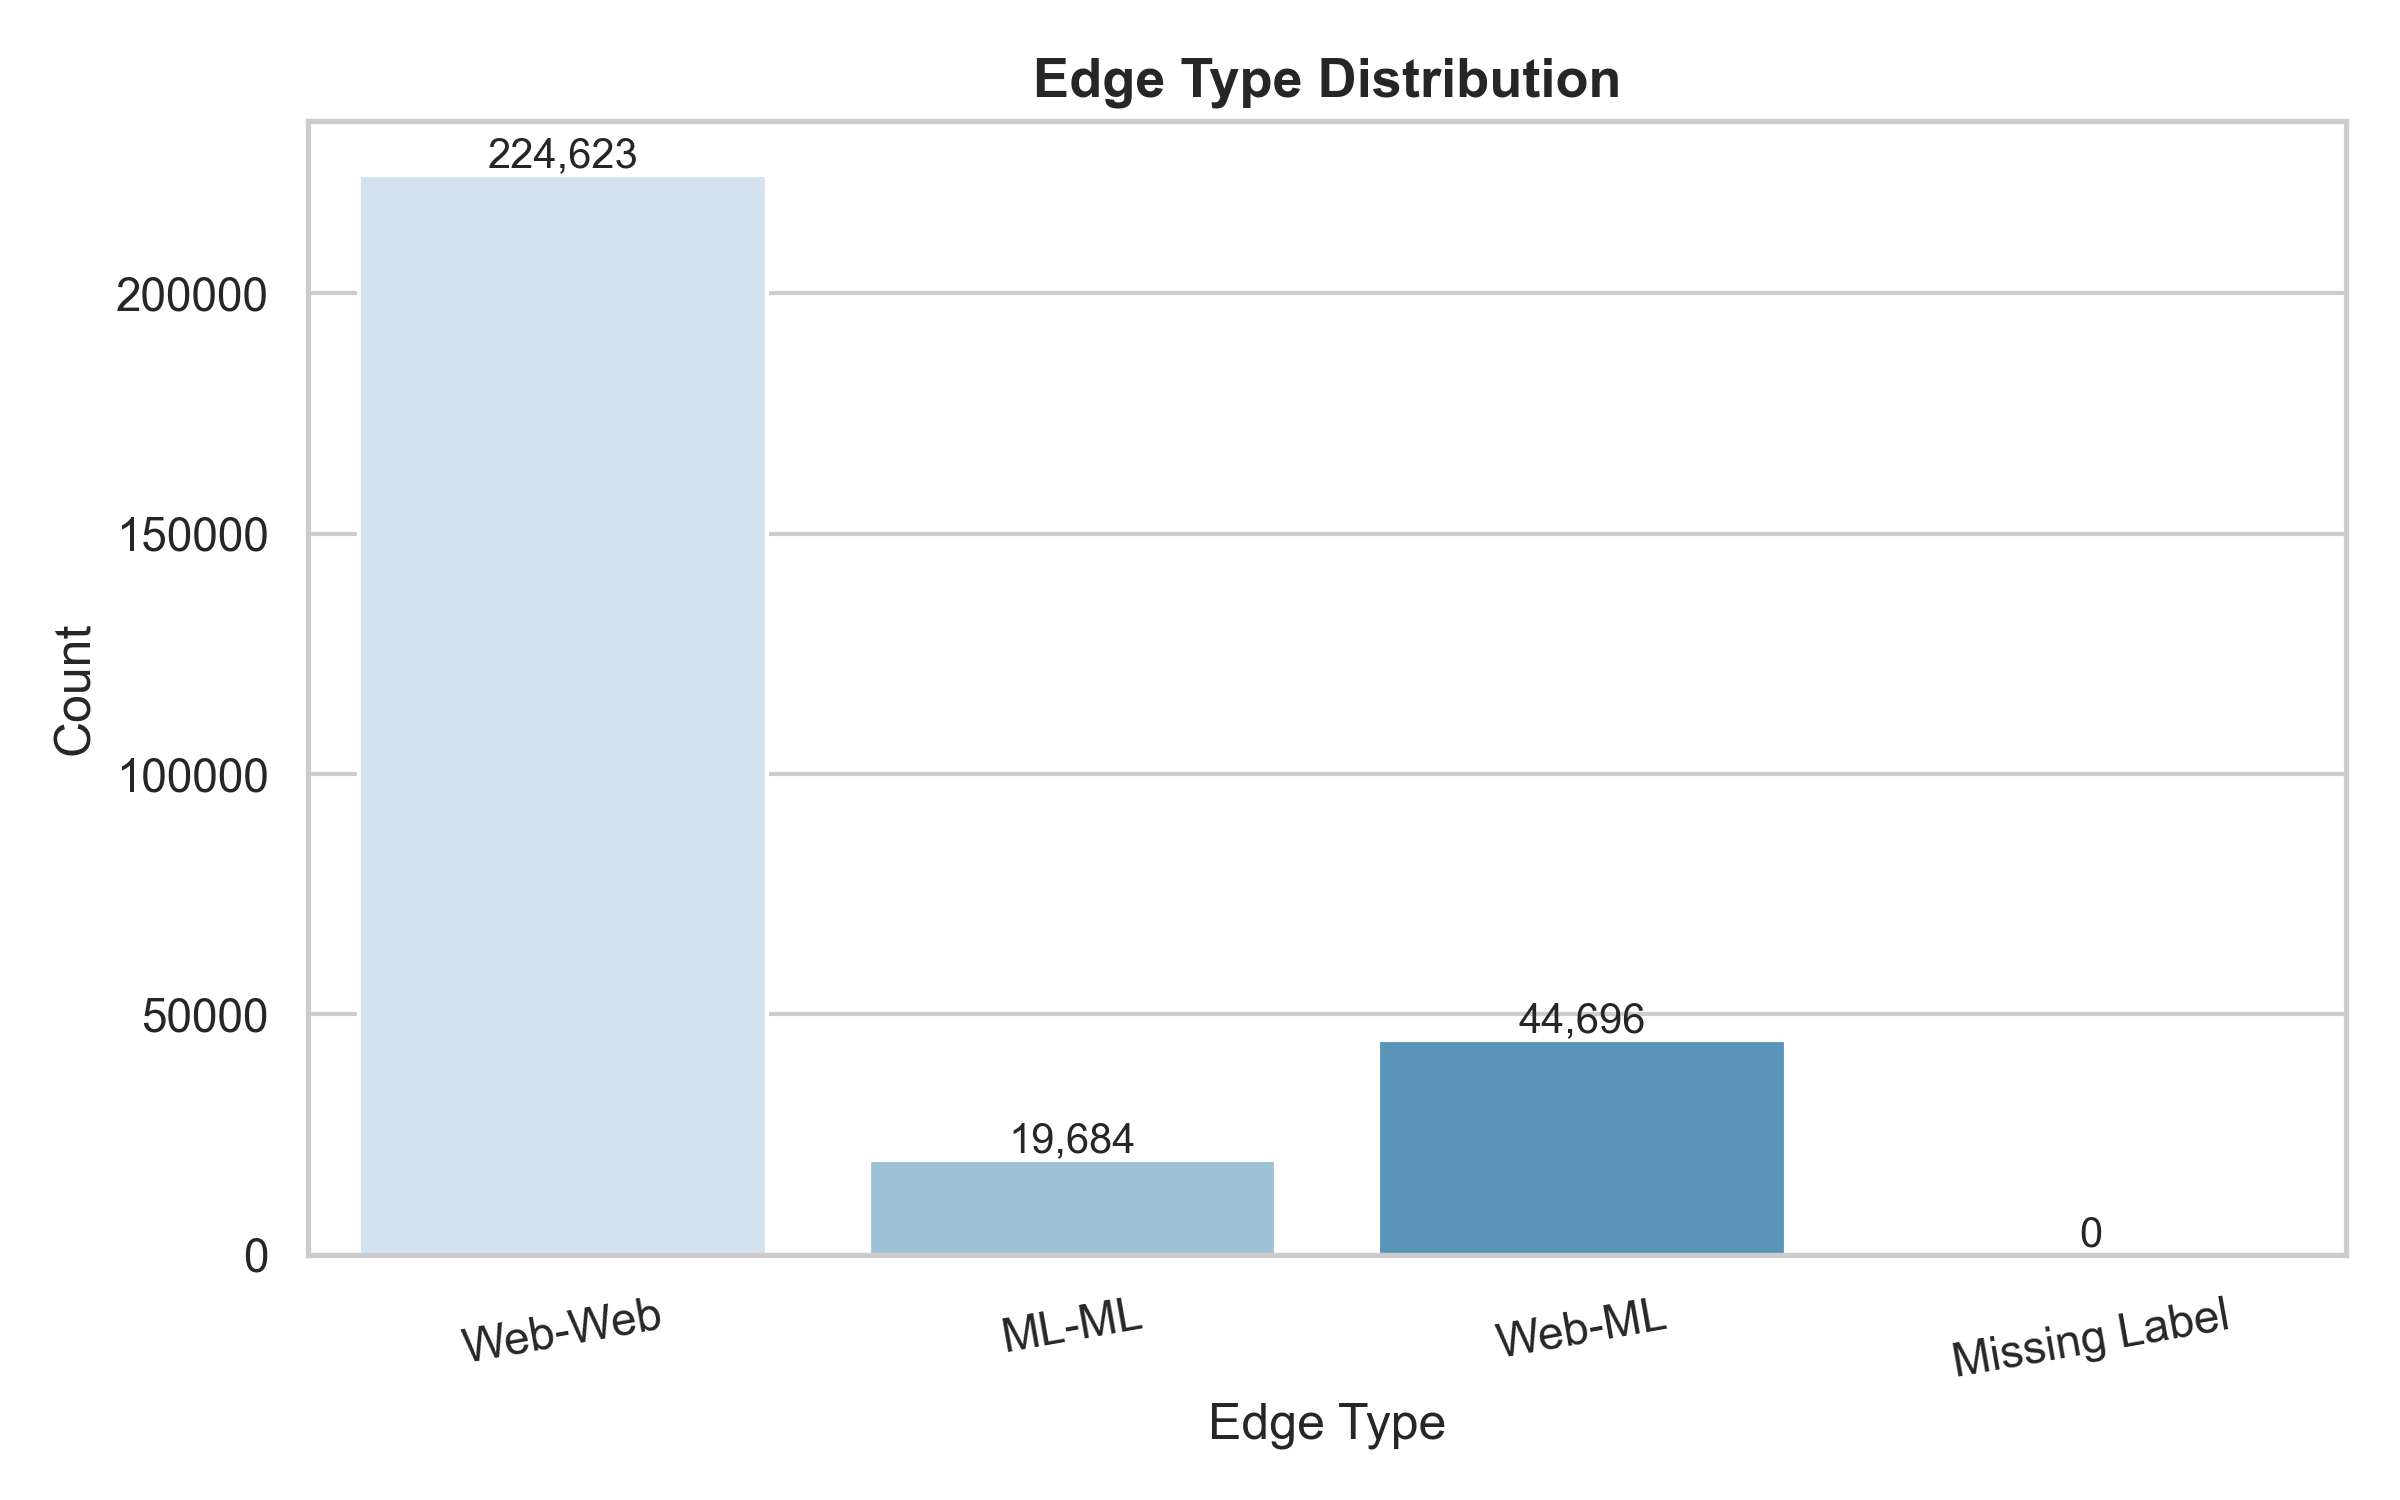

In [18]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/figures/edge_type_distribution.png')))

**Figure note.** Web-Web edges are most frequent, while the combined within-field share is much larger than the cross-field share.

<h3>Table: <code>outputs/tables/centrality_top_overlap.csv</code></h3>

Top-20 overlap between the centrality rankings.

In [19]:
centrality_overlap = pd.read_csv(ROOT / 'outputs/tables/centrality_top_overlap.csv')
display(centrality_overlap)

,metric_a,metric_b,top_k,intersection_count,jaccard_overlap
0,Degree Centrality,PageRank,20,20,1.000000
1,Degree Centrality,"Betweenness Centrality (approx., k=100)",20,15,0.600000
2,Degree Centrality,Clustering Coefficient,20,0,0.000000
3,Degree Centrality,HITS Hub,20,17,0.739130
4,PageRank,"Betweenness Centrality (approx., k=100)",20,15,0.600000
5,PageRank,Clustering Coefficient,20,0,0.000000
6,PageRank,HITS Hub,20,17,0.739130
7,"Betweenness Centrality (approx., k=100)",Clustering Coefficient,20,0,0.000000
8,"Betweenness Centrality (approx., k=100)",HITS Hub,20,14,0.538462
9,Clustering Coefficient,HITS Hub,20,0,0.000000


**Conclusion.** Degree and PageRank identify nearly the same hubs, while sampled betweenness and clustering capture different roles.

<h3>Main centrality takeaway</h3>

Node 31890 (`dalinhuang99`) leads Degree and PageRank, while node 27803 (`nfultz`) leads sampled Betweenness. The named contrast preserves the useful result from the original combined analysis without duplicating its workflow.

<h2>Summary</h2>

In this notebook we looked at the basic shape of the network. We checked label counts, edge types, degree patterns, centrality, and a sampled network picture. The main point is that the graph is not random-looking: some nodes are much more connected, and many links connect developers from the same field. These patterns explain why graph features may help in the next steps.